# Mini-projet Data Mining — Détection automatique des crises d'absence à partir de signaux EEG

**Partie I — Compréhension et exploration des données (Questions 1 et 2)**

Binôme : *à compléter* · Enregistrement étudié : `230102B_F_0000`

Le code de traitement est regroupé dans le paquet `src/`, à la racine du projet ; ce notebook
appelle ces fonctions et commente les résultats.

| Module | Rôle |
| --- | --- |
| `src/data.py` | lecture des fichiers MATLAB, des marqueurs, des annotations Excel |
| `src/preprocessing.py` | filtrage du signal (coupe-bande secteur, passe-bande 0,5–40 Hz) |
| `src/visualization.py` | figures (signal, montage multi-canaux, spectre) |

Dépendances : `numpy`, `pandas`, `scipy`, `matplotlib`, `openpyxl`
→ `pip install numpy pandas scipy matplotlib openpyxl`

## 0. Configuration

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Racine du projet : le dossier qui contient `src/` et `data/`.
CURRENT = Path.cwd().resolve()
ROOT = next(
    folder
    for folder in [CURRENT, *CURRENT.parents]
    if (folder / "src" / "data.py").is_file()
)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import (
    channel_quality,
    list_recordings,
    load_recording,
    load_seizure_annotations,
    match_recording_id,
    saturation_report,
    summarize,
)
from src.preprocessing import clean_recording, mains_frequency
from src import visualization as viz

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.dpi"] = 110

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)


def save(name):
    """Enregistre la figure courante dans reports/figures puis l'affiche."""
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()


print("Projet :", ROOT)

Projet : /sessions/rcw-01xh5rdxsd8pevgm8tapjth5/mnt/DataMining


### Enregistrements disponibles

Chaque enregistrement est fourni en deux fichiers : `...d.mat` contient le signal,
`...h.mat` contient les marqueurs posés par le manipulateur pendant l'examen.

In [2]:
display(list_recordings(ROOT))

,recording_id,data_file,header_file,size_mb
0,190304A_E_0000,190304A_E_0000d.mat,190304A_E_0000h.mat,50.55
1,191113A_D_0000,191113A_D_0000d.mat,191113A_D_0000h.mat,41.70
2,200625A_F_0000,200625A_F_0000d.mat,200625A_F_0000h.mat,27.56
3,210204B_C_0000,210204B_C_0000d.mat,210204B_C_0000h.mat,29.91
4,210208B_G_0000,210208B_G_0000d.mat,210208B_G_0000h.mat,26.68
5,210406A_F_0000,210406A_F_0000d.mat,210406A_F_0000h.mat,45.31
6,210427B_C_0000,210427B_C_0000d.mat,210427B_C_0000h.mat,28.31
7,210504B_C_0000,210504B_C_0000d.mat,210504B_C_0000h.mat,62.61
8,210914B_A_0000,210914B_A_0000d.mat,210914B_A_0000h.mat,23.31
9,210928B_B_0000,210928B_B_0000d.mat,210928B_B_0000h.mat,27.51


## Question 1 — Chargement du fichier et description des données

**Format des fichiers.** Les fichiers `.mat` ne contiennent pas une simple matrice mais un
`timetable` MATLAB, enregistré comme objet (système MCOS). `scipy.io.loadmat` ne sait pas
décoder ce type et renvoie un objet vide : les valeurs sont en réalité rangées dans la
variable cachée `__function_workspace__`, qui est elle-même un mini fichier MAT.

La fonction `load_recording` relit cet espace de travail, retrouve la structure du timetable
**par ses champs** (et non par une position fixe, qui changerait d'un fichier à l'autre),
puis reconstruit le signal :

1. le signal est stocké par blocs d'une seconde → on concatène les blocs de chaque canal ;
2. les instants (`rowTimes`) sont un `duration` MATLAB, donc exprimés en **millisecondes** ;
3. la fréquence d'échantillonnage se déduit de `nombre d'échantillons par bloc / durée du bloc`.

In [3]:
RECORDING_ID = "230102B_F_0000"

recording = load_recording(RECORDING_ID, ROOT)
recording

Recording(230102B_F_0000, 313600 echantillons, 21 canaux, 256 Hz, 1225 s)

### Tableau de synthèse

In [4]:
display(summarize(recording))

,Propriete,Valeur
0,Fichier de signal,230102B_F_0000d.mat
1,Fichier d'entete,230102B_F_0000h.mat
2,Nombre de lignes (echantillons),313 600
3,Nombre de variables (colonnes),22
4,dont canaux de mesure,21
5,dont canaux EEG,19
6,Canaux non EEG,"SLI, ECG"
7,Frequence d'echantillonnage,256.0 Hz
8,Periode d'echantillonnage,3.906 ms
9,Duree totale,1225.0 s (20 min 25.0 s)


**Réponses à la Question 1**

| Élément demandé | Valeur |
| --- | --- |
| Nombre de lignes | 313 600 échantillons |
| Nombre de variables | 22 colonnes = 1 colonne de temps + 21 canaux (19 EEG + SLI + ECG) |
| Fréquence d'échantillonnage | 256 Hz (période de 3,906 ms) |
| Durée totale | 1 225 s, soit 20 min 25 s |
| Valeurs manquantes | 0 (aucun NaN, aucune valeur infinie) |

*Unités* : le temps est en secondes ; l'unité d'amplitude n'est **pas** enregistrée dans le
fichier (le champ `varUnits` du timetable est vide). Le microvolt est la convention en EEG,
et l'ordre de grandeur du signal filtré (quelques dizaines de µV, voir Question 2) le confirme.

### Premières lignes du fichier

In [5]:
display(recording.data.head().round(2))

,Time,EEGFp1,EEGFp2,EEGF7,EEGF3,EEGFz,EEGF4,EEGF8,EEGT4,EEGC4,EEGCz,EEGC3,EEGT3,EEGT5,EEGP3,EEGPz,EEGP4,EEGT6,EEGO2,EEGO1,SLI,ECG
0,0.00,519.16,809.65,631.20,-19.42,2631.40,1.34,818.96,8.32,407.11,677.20,-131.11,358.96,92.98,678.81,246.74,181.94,-165.12,135.23,329.43,0.09,3126.66
1,0.00,329.79,591.29,443.80,-208.07,2528.66,-198.59,594.51,-169.59,187.85,479.42,-311.71,169.95,-96.74,488.73,40.00,-104.44,-350.55,-51.64,152.95,0.09,3309.94
2,0.01,199.84,466.35,312.07,-339.09,2381.17,-329.61,466.71,-299.00,39.82,351.26,-440.58,41.97,-230.27,358.42,-91.55,-242.98,-476.91,-178.36,15.84,0.09,3449.91
3,0.01,298.64,601.13,412.30,-237.79,2620.66,-219.53,607.40,-205.03,161.18,462.77,-344.11,146.32,-128.42,461.88,24.25,-48.24,-373.82,-75.09,103.90,0.09,3377.78
4,0.02,497.86,818.96,617.96,-32.49,2880.37,-9.04,835.07,-3.13,401.74,675.23,-139.16,353.95,82.60,670.94,242.80,234.21,-166.19,134.33,310.28,0.09,3196.64


### Contrôle de qualité canal par canal

Aucune valeur manquante, mais trois remarques utiles pour la suite :

* les amplitudes brutes atteignent plusieurs milliers d'unités, très au-dessus d'un EEG
  physiologique : il s'agit d'artefacts et d'une composante continue ;
* les canaux `SLI` (stimulation lumineuse) et `ECG` ne sont pas de l'EEG et seront exclus
  de l'extraction de caractéristiques ;
* « zéro valeur manquante » ne veut pas dire « zéro valeur inutilisable » : certains
  échantillons sont **saturés**, c'est-à-dire collés à la butée du convertisseur.

In [6]:
display(channel_quality(recording))

,canal,type,manquantes,infinies,min,max,moyenne,ecart_type
0,EEGFp1,EEG,0,0,-2781.03,5823.30,253.29,218.04
1,EEGFp2,EEG,0,0,-2508.79,5815.42,513.78,215.43
2,EEGF7,EEG,0,0,-2737.36,5818.82,361.76,217.37
3,EEGF3,EEG,0,0,-3344.13,5862.67,-214.44,217.35
4,EEGFz,EEG,0,0,-5865.00,5865.00,46.85,1450.09
5,EEGF4,EEG,0,0,-3339.83,5858.91,-211.87,219.58
6,EEGF8,EEG,0,0,-2560.70,5825.44,521.82,222.44
7,EEGT4,EEG,0,0,-3325.33,5865.00,-198.92,220.46
8,EEGC4,EEG,0,0,-3251.95,5843.52,173.06,235.70
9,EEGCz,EEG,0,0,-2698.70,5811.84,420.53,282.36


Le tableau suivant compte ces échantillons saturés. Le résultat rejoint les marqueurs de
l'entête, qui signalent explicitement « SATURATION DES VOIES : Fz / ECG » :
l'ECG et le canal `Fz` sont les plus touchés, et le canal `SLI` est constant sur tout
l'enregistrement (aucune information). Ces trois canaux seront écartés des caractéristiques.

In [7]:
display(saturation_report(recording).head(8))

,canal,maximum_absolu,echantillons_satures,pourcentage,ecart_type,remarque
0,ECG,5865.0,2428,0.774,1236.5,saturation
1,EEGFz,5865.0,57,0.018,1450.1,saturation
2,EEGT4,5865.0,2,0.001,220.5,saturation
3,EEGF3,5862.7,1,0.000,217.4,
4,EEGPz,5865.0,1,0.000,238.7,
5,EEGP4,5865.0,1,0.000,248.5,
6,EEGT6,5865.0,1,0.000,225.9,
7,EEGC3,5861.4,1,0.000,223.5,


### Marqueurs de l'examen (fichier `*h.mat`)

Le fichier d'entête contient les événements notés pendant l'enregistrement : début de
l'examen, yeux ouverts (`YO`) / yeux fermés (`YF`), hyperpnée (`HPN`, 3 minutes),
stimulation lumineuse intermittente (`SLI=3Hz` à `SLI=25Hz`) et saturations de voies.
Ces manœuvres sont précisément celles qui provoquent les absences : elles aident à lire
le tracé, même si elles ne remplacent pas les annotations de crises.

In [8]:
display(recording.events)

,onset_s,label,duration_s
0,0.007812,Début,NaN
1,4.375000,SATURATION DES VOIES : Fz ECG,NaN
2,9.375000,SATURATION DES VOIES : Fz,NaN
3,19.375000,SATURATION DES VOIES : Fz ECG,NaN
4,69.375000,SATURATION DES VOIES : ECG,NaN
5,157.625000,YO,NaN
6,176.375000,YF,NaN
7,179.937500,HPN 3mn début,NaN
8,199.718750,HPN - 00:00:20,NaN
9,219.562500,HPN - 00:00:40,NaN


## Question 2 — Représentation du signal EEG en fonction du temps

### 2.1 Signal brut

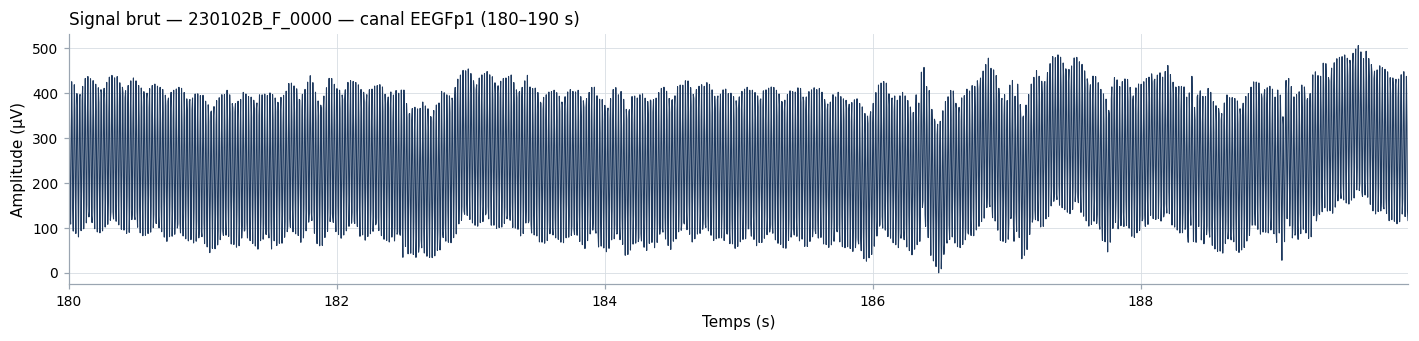

In [9]:
ax = viz.plot_signal(
    recording,
    channel="EEGFp1",
    start=180,
    end=190,
    title=f"Signal brut — {RECORDING_ID} — canal EEGFp1 (180–190 s)",
)
save("q2_1_signal_brut")

Le tracé brut est illisible : une oscillation très rapide sature la figure et le signal
oscille autour de +250 µV au lieu de zéro. Le spectre ci-dessous donne l'explication.

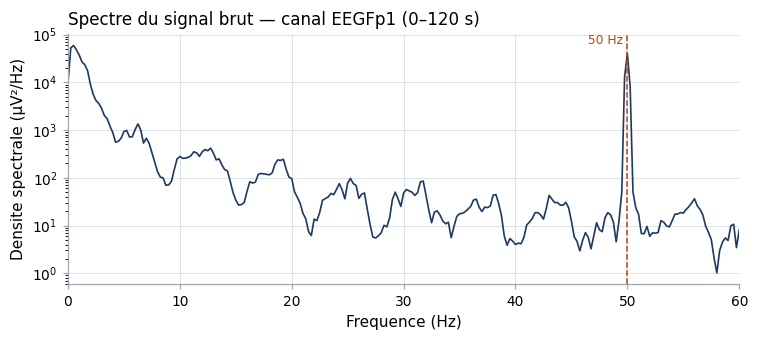

In [10]:
ax = viz.plot_spectrum(
    recording,
    channel="EEGFp1",
    start=0,
    end=120,
    title="Spectre du signal brut — canal EEGFp1 (0–120 s)",
)
save("q2_2_spectre_brut")

La raie à **50 Hz** (réseau électrique) domine tout le spectre, et une dérive très lente
ajoute la composante continue. Deux filtres suffisent à rendre le signal exploitable :

* un **coupe-bande** (notch) à 50 Hz ;
* un **passe-bande 0,5–40 Hz**, qui est la bande utile de l'EEG et contient les rythmes
  Delta, Theta, Alpha et Beta étudiés en Partie VI.

Les deux filtres sont appliqués en aller-retour (`filtfilt`) pour ne pas décaler le signal
dans le temps : une crise reste ainsi au bon endroit sur l'axe des temps.

In [11]:
print("Fréquence du secteur détectée :", mains_frequency(
    recording.channel("EEGFp1"), recording.sampling_rate), "Hz")

clean = clean_recording(recording)
print("Prétraitement appliqué :", clean.source["preprocessing"])

Fréquence du secteur détectée : 50.0 Hz


Prétraitement appliqué : notch 50 Hz + passe-bande 0.5-40.0 Hz


### 2.2 Signal filtré — même fenêtre de 10 secondes

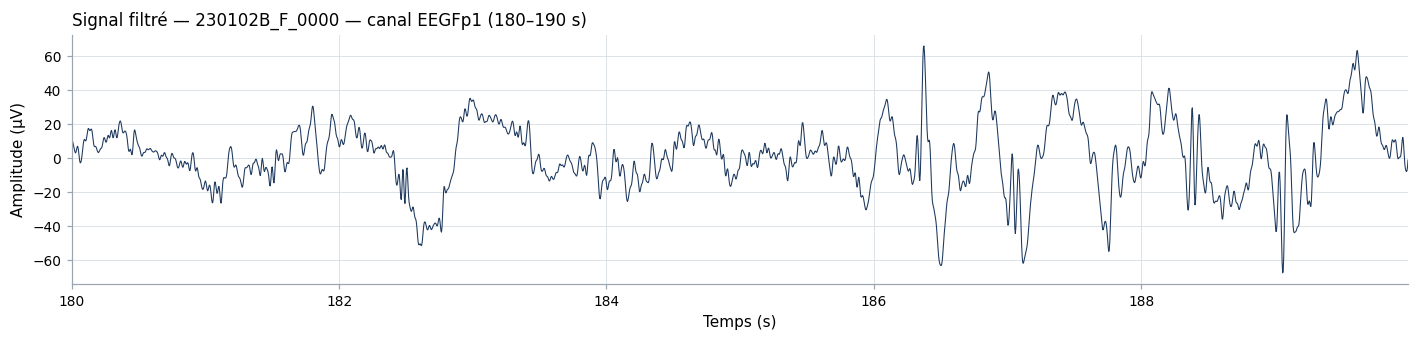

In [12]:
ax = viz.plot_signal(
    clean,
    channel="EEGFp1",
    start=180,
    end=190,
    title=f"Signal filtré — {RECORDING_ID} — canal EEGFp1 (180–190 s)",
)
save("q2_3_signal_filtre")

L'activité cérébrale apparaît : amplitude de ±50 µV environ, ce qui correspond bien à un
EEG de surface exprimé en microvolts.

### 2.3 Vue d'ensemble de l'enregistrement

L'axe vertical est cadré sur 99,5 % des valeurs, sinon quelques artefacts de plusieurs
centaines de microvolts écraseraient le reste du tracé. Les traits verticaux sont les
marqueurs de l'examen.

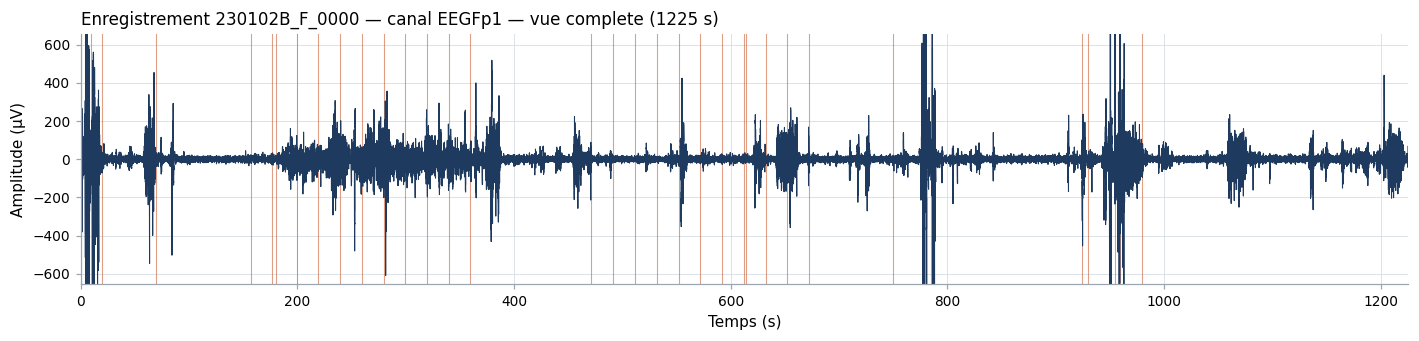

In [13]:
ax = viz.plot_overview(clean, channel="EEGFp1")
save("q2_4_vue_complete")

### 2.4 Montage multi-canaux

Affichage de type clinique : les 19 canaux EEG empilés, chacun centré sur sa moyenne.

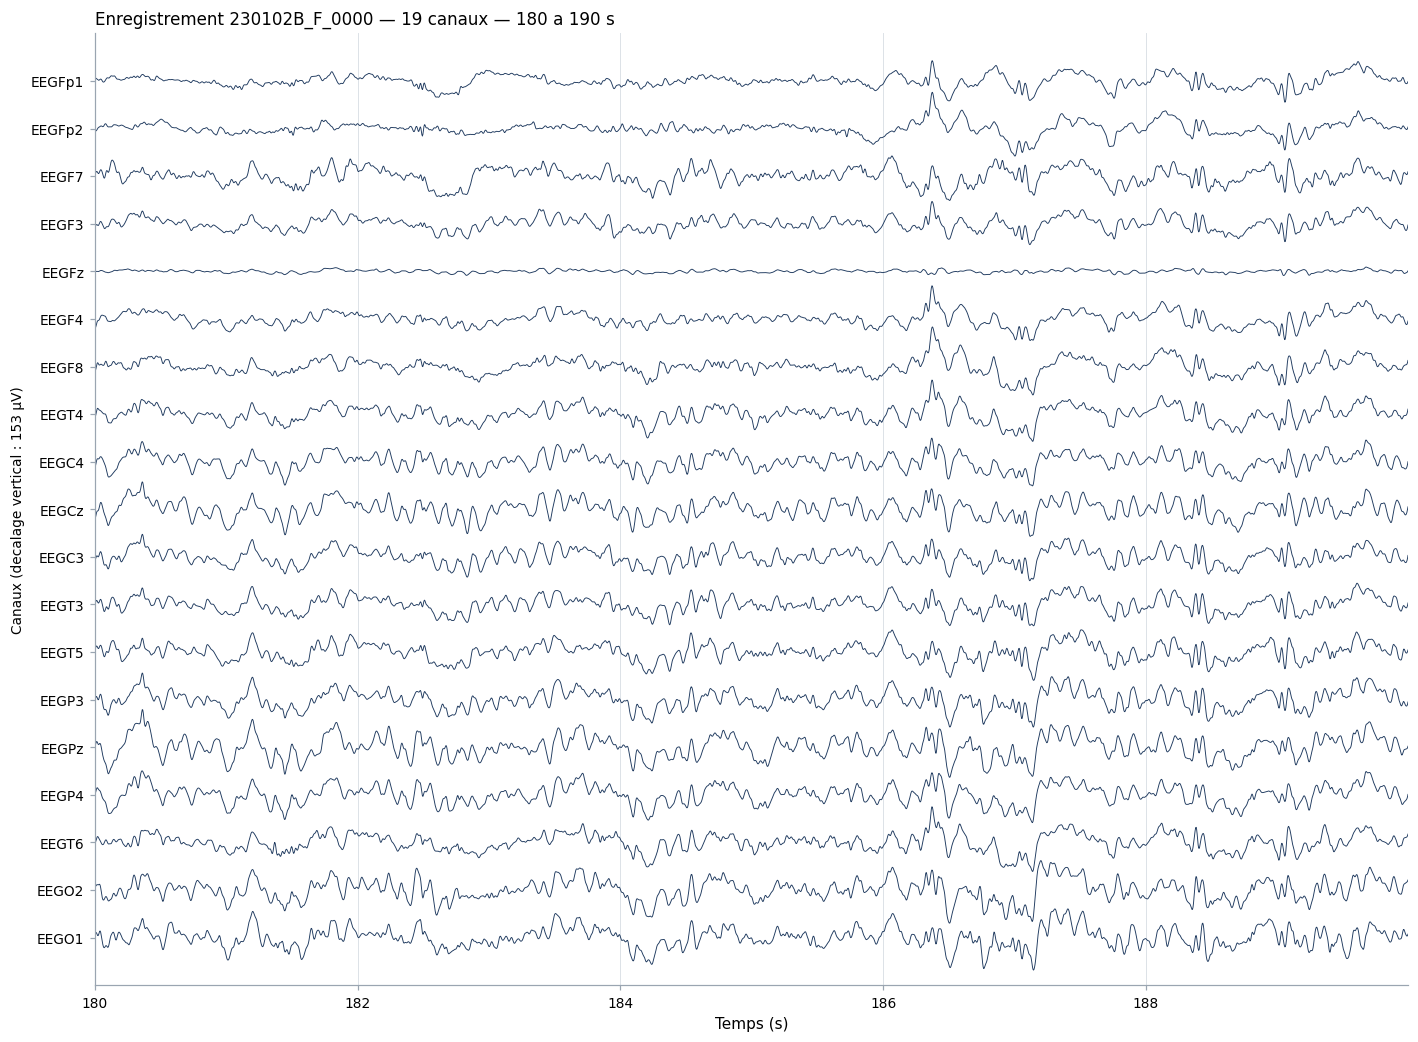

In [14]:
ax = viz.plot_montage(clean, start=180, end=190)
save("q2_5_montage_repos")

## Question — Que remarque-t-on visuellement pendant les crises ?

L'épisode ci-dessous (vers 277–283 s, pendant l'hyperpnée) montre le motif recherché.

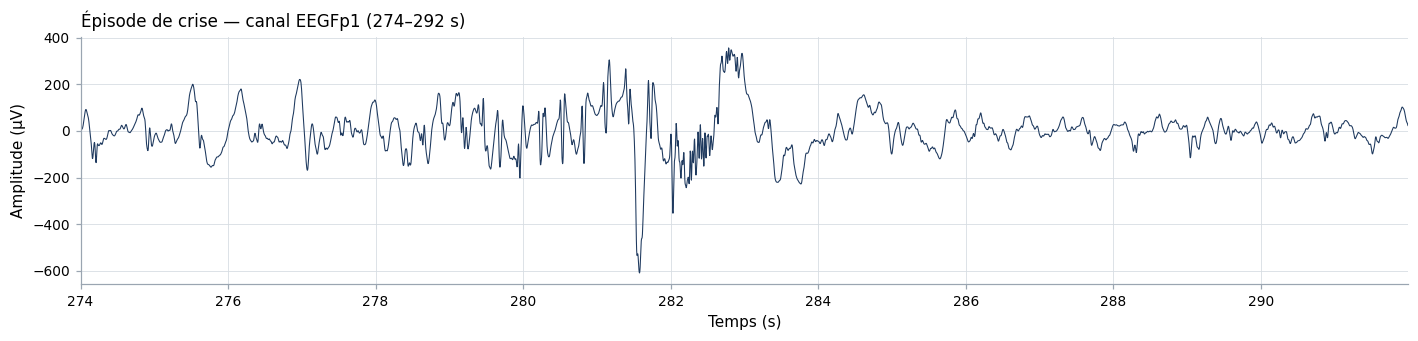

In [15]:
ax = viz.plot_signal(
    clean,
    channel="EEGFp1",
    start=274,
    end=292,
    title="Épisode de crise — canal EEGFp1 (274–292 s)",
)
save("q2_6_crise_zoom")

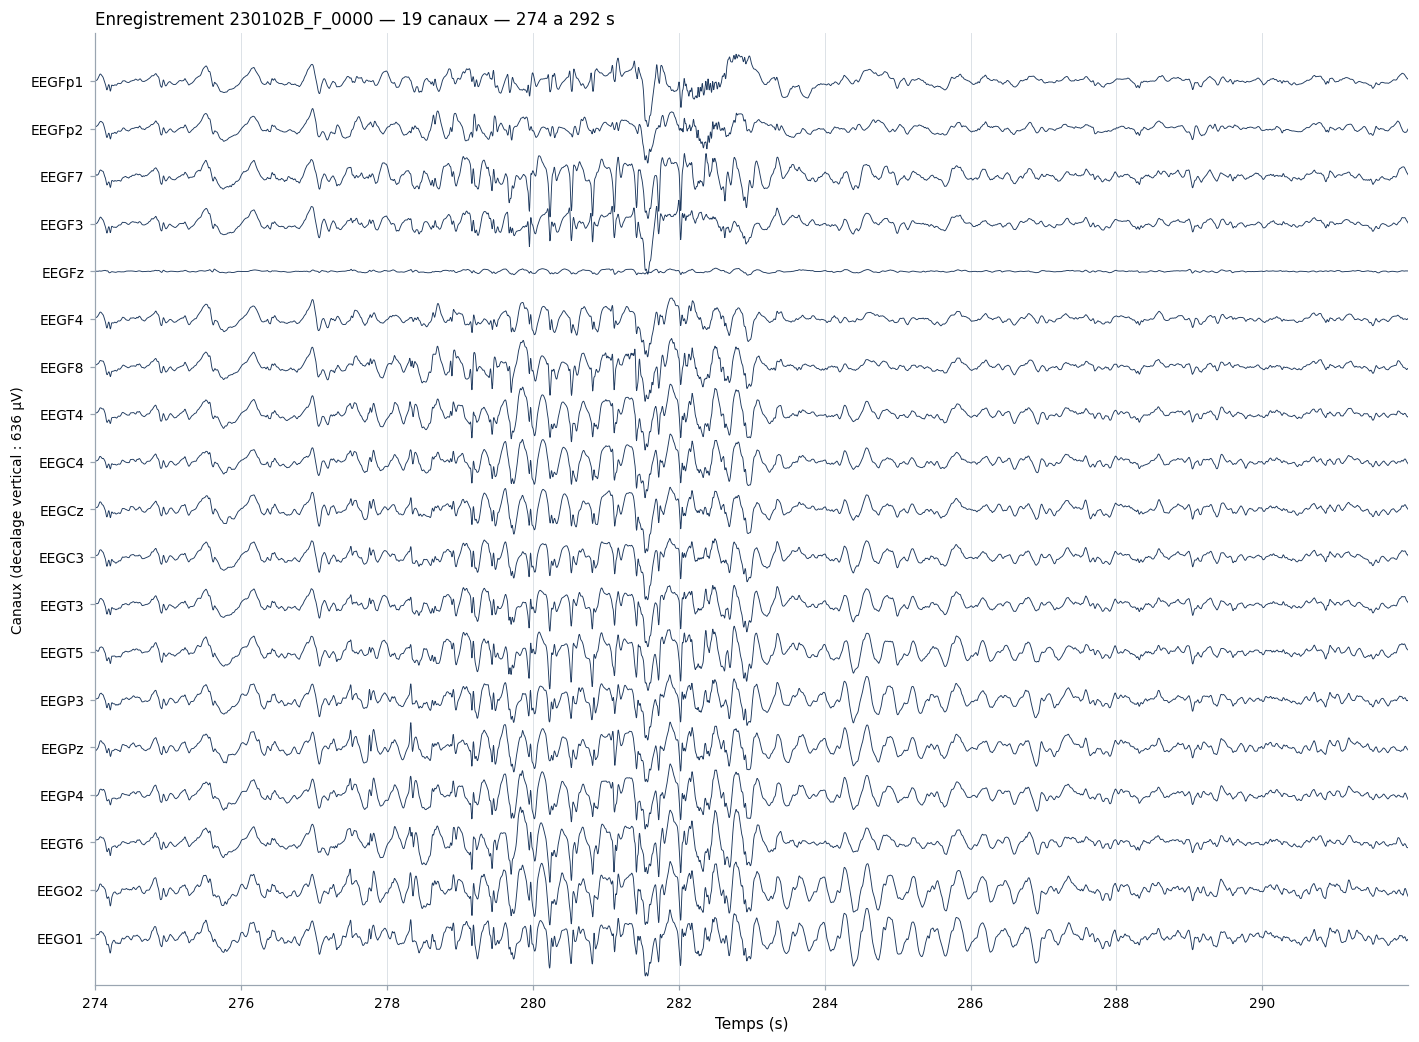

In [16]:
ax = viz.plot_montage(clean, start=274, end=292)
save("q2_7_crise_montage")

**Observations**

1. **Amplitude** : elle est multipliée par 3 à 5 pendant l'épisode (±200 µV contre ±50 µV
   hors crise). C'est ce que mesureront l'écart-type, l'amplitude crête à crête, le RMS et
   l'énergie de la Partie V.
2. **Rythme** : le tracé devient très régulier, autour de 3 cycles par seconde
   (pointe-onde à 3 Hz, motif caractéristique de l'absence). Hors crise le tracé est
   irrégulier et plus rapide. La puissance Delta/Theta de la Partie VI devrait donc bien
   séparer les deux classes.
3. **Généralisation** : le motif apparaît en même temps sur *tous* les canaux, alors que les
   artefacts (clignements, mouvements) ne touchent que quelques électrodes.
4. **Début et fin nets** : l'épisode démarre et s'arrête brutalement, ce qui justifie de
   découper le signal en fenêtres de 2 s (Partie IV) plutôt que de travailler échantillon
   par échantillon.

## Point à régler avant la Partie II

Les annotations de `Crises absences.xlsx` sont des **heures de la journée** (fractions de
journée Excel : `0,504062` → 12 h 05 min 51 s), alors que le signal commence à `t = 0 s`.
Le fichier `.mat` ne contient pas l'heure de début de l'enregistrement : il manque donc
une origine commune pour convertir les annotations en secondes depuis le début du tracé.

Deux vérifications rassurantes sur cet enregistrement :

* les 9 crises annotées s'étalent sur 1 162 s, ce qui tient bien dans les 1 225 s enregistrées ;
* les durées annotées (8 à 24 s) correspondent à des absences typiques.

La cellule suivante affiche les annotations brutes ; le décalage à appliquer sera établi
en Partie II (à confirmer avec l'encadrant).

In [17]:
annotations = load_seizure_annotations(ROOT)
seizures = annotations[
    annotations["recording_id"].str.upper() == match_recording_id(RECORDING_ID)
]

display(seizures[["recording_id", "seizure", "start_s", "end_s", "duration_s"]])

print("Nombre de crises annotées :", len(seizures))
print("Étendue des annotations : %.0f s" % (seizures["end_s"].max() - seizures["start_s"].min()))
print("Durée de l'enregistrement : %.0f s" % recording.duration)

,recording_id,seizure,start_s,end_s,duration_s
72,230102B-F,1,43551.0,43560.0,9.0
73,230102B-F,2,43723.0,43739.0,16.0
74,230102B-F,3,43770.0,43780.0,10.0
75,230102B-F,4,43866.0,43880.0,14.0
76,230102B-F,5,43947.0,43955.0,8.0
77,230102B-F,6,44134.0,44154.0,20.0
78,230102B-F,7,44449.0,44473.0,24.0
79,230102B-F,8,44551.0,44568.0,17.0
80,230102B-F,9,44696.0,44713.0,17.0


Nombre de crises annotées : 9
Étendue des annotations : 1162 s
Durée de l'enregistrement : 1225 s
